In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

In [3]:
# neural_root = '/home/wx2203/Weihao/data_locker/step_2/'
prefix = '/mnt/staging/' # or 
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"

data_root =  str(PREPARES / "epochs-rest-to-running") + "/"
figure_config_root = str(PREPARES / "config") + "/"
save_root = str(FIGURES / "figure3") + "/"
mouse='cm125'

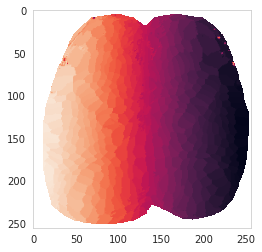

In [4]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
plt.imshow(IDX_sorted)

In [5]:
sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+mouse)
motor_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
mouth_S1_ind = sensory_ind['mouth']
extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse)
extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse)
sensory_ind['LM']=sensory_ind['mouth']
sensory_ind['RM']=extra_extra_ind['right_mouth_sensory']


In [6]:
load_list = ['norm_M_jrgeco', 'norm_M_rotf', 'norm_M_face_pc', 'norm_M_body_pc', 'norm_M_pupil_pc_norm', 
 'norm_M_whisk_vel_norm', 'norm_M_nose_vel_norm', 'norm_M_LFP_vel_norm', 'norm_M_RFP_vel_norm',
 'M_day_label', 'M_is_groom', 'M_ind', 'norm_M_mirrorRFP_vel_norm', 'norm_M_mirrorLFP_vel_norm', 
 'norm_M_mirrorRHP_vel_norm', 'norm_M_mirrorLHP_vel_norm']

f = scipy.io.loadmat(data_root+'final_'+mouse+'_norm.mat')

for item in load_list:
    exec("{}=np.squeeze(f['{}'])".format(item,item))
T_PRE=200;
T_POST=300;
T=T_PRE+T_POST

In [20]:
choice_body_part_dict = {0:'RHP',1:'RFP',2:'RW',3:'RV',
                         4:'RM_M2',5:'RFP_M2',6:'LatM'}
choice_dict = {0:316,1:400,2:sensory_ind['RW'],3:406,4:[],5:[],6:418}

In [21]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

palatte_dict['RM_M2']=palatte_dict['LM']
palatte_dict['RFP_M2']='#d6128b'
palatte_dict['RFP_M1']='#C44B30'

In [9]:
M_raw={}
t1 = 340
with h5py.File(step_1_root+'{}/{}/{}_stim_1.mat'.format(mouse,'1','runB'),'r') as f_H: 
    for key in ['green','lime','red']:
        C = np.array(f_H['C'][key])
        S = np.array(f_H['S'][key])[t1:t1+1,:]
        CS = np.dot(S,C).transpose()

        temp = CS
        temp = temp.reshape((256,256,-1)).transpose((1,0,2))     

        # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
        M_raw[key] = temp


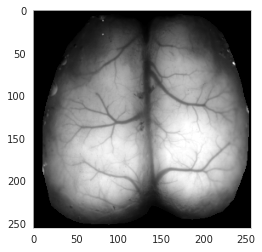

In [10]:
masked_brain = np.multiply(np.squeeze(M_raw['lime']),mask)
masked_brain=np.nan_to_num(masked_brain,0)
plt.imshow(masked_brain,cmap='gray',vmin=500,vmax=4500)

# business

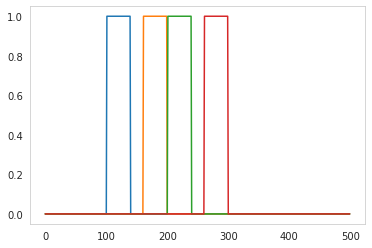

In [11]:
T = norm_M_body_pc.shape[0]
t_ax = np.divide(range(-T_PRE,T-T_PRE),20)

win1 = np.logical_and(t_ax>-5,t_ax<-3)
win2 = np.logical_and(t_ax>-2,t_ax<-0)
win3 = np.logical_and(t_ax>0,t_ax<2)
win4 = np.logical_and(t_ax>3,t_ax<5)


plt.plot(win1)
plt.plot(win2)
plt.plot(win3)
plt.plot(win4)
# plt.xlim([290,300])|

In [12]:
# zscore Delta_F/F 
norm_M_jrgeco_zscore = norm_M_jrgeco.copy()
norm_M_jrgeco_zscore = stats.zscore(norm_M_jrgeco_zscore,axis=1)
ss = norm_M_jrgeco.shape
norm_M_jrgeco_zscore_std = np.empty((ss[0],ss[1],0))
for i_bout in range(ss[2]):
    temp = pd.DataFrame(norm_M_jrgeco_zscore[:,:,i_bout]).T.rolling(20).std().T.values
    norm_M_jrgeco_zscore_std=np.append(norm_M_jrgeco_zscore_std,temp[:,:,np.newaxis],axis=2)


In [13]:
load_filename = data_root+'final_'+mouse+'_MM_full.h5'
# Load and baseline-subtract in blocks of 16 rows. The original built a second
# full-size array here (np.array(...), then MM_jrgeco - np.mean(...)), so it needed two
# copies of the stack live at once: 2 x 31.7 GB = 63.5 GB for cm125, which OOM-kills a
# 48 GB machine (exit 137). This holds one 31.7 GB array plus one ~2 GB block, and
# reads stay sequential; measured on an M4 Pro it finishes in 49 s with 6.4 GB max
# resident.
# Bit-identical to the original: np.array_equal(..., equal_nan=True) is True, because
# blocking along axis 0 leaves the axis-2 reduction untouched. See
# a memory-safe chunked loader.
with h5py.File(load_filename, 'r') as hf:
    dset = hf['MM_jrgeco']
    MM_jrgeco = np.empty(dset.shape, dtype=dset.dtype)
    for i_x0 in range(0, dset.shape[0], 16):
        blk = dset[i_x0:i_x0 + 16]
        MM_jrgeco[i_x0:i_x0 + 16] = blk - np.mean(blk[:,:,T_PRE-100:T_PRE,:],2)[:,:,np.newaxis,:]
    del blk, dset

In [14]:
dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')

list_choice_M2_l_n_r = ['RFP','RM','RW','RHP','LFP','LM','LW','LHP']
seed_ROI_xy = dict_seed_ROI_xy_mice[mouse]

jrgeco2plot_M2 = {};node_coords_M2 = {}
for i_bdp in range(8):
    bdp = list_choice_M2_l_n_r[i_bdp]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    node_coords_M2[bdp] = np.array([(y_top_left+y_botton_right)/2,(x_top_left+x_botton_right)/2])
    small_roi_tcs = np.nanmean(np.nanmean(
        MM_jrgeco[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    jrgeco2plot_M2[bdp] = small_roi_tcs
    
H_jrgeco_new_bsl=getH_4D(MM_jrgeco,IDX_sorted)

In [22]:
jrgeco2plot ={}
norm_jrgeco_zscored_std = {}
for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    if len(bdp.split('_'))==1:
        jrgeco2plot[bdp]=H_jrgeco_new_bsl[ind,:,:]
        norm_jrgeco_zscored_std[bdp] = pd.DataFrame(stats.zscore(jrgeco2plot[bdp],axis=0)).rolling(20,axis=0).std().values
    else:
        if bdp.split('_')[1] == 'M2':
            jrgeco2plot[bdp] = jrgeco2plot_M2[bdp.split('_')[0]]
            norm_jrgeco_zscored_std[bdp] = pd.DataFrame(stats.zscore(jrgeco2plot[bdp],axis=0)).rolling(20,axis=0).std().values
        else:
            jrgeco2plot[bdp] = jrgeco2plot[bdp.split('_')[0]]
            norm_jrgeco_zscored_std[bdp] = pd.DataFrame(stats.zscore(jrgeco2plot[bdp],axis=0)).rolling(20,axis=0).std().values


In [23]:

map_norm_H_by_win = {}
map_norm_H_zscore_std_by_win = {}
for i_win,win in enumerate(['win1','win2','win3','win4']):
    map_norm_H_by_win[win] = {}
    for i_bdp in range(7):
        bdp = choice_body_part_dict[i_bdp]
        exec("temps = np.mean(jrgeco2plot[bdp][{},:],axis=0)".format(win))
        map_norm_H_by_win[win][bdp]=temps

    map_norm_H_zscore_std_by_win[win]={}
    for i_bdp in range(7):
        bdp = choice_body_part_dict[i_bdp]
        exec("temps = np.mean(norm_jrgeco_zscored_std[bdp][{},:],axis=0)".format(win))
        map_norm_H_zscore_std_by_win[win][bdp]=temps


In [24]:
diff_pot,paired_t_pot=pd.DataFrame(),pd.DataFrame()
for i_region,key in enumerate(choice_body_part_dict):
    region = choice_body_part_dict[key]
    ind = choice_dict[key]
    
    diff_temp=pd.DataFrame()
    paired_t_temp=pd.DataFrame(columns=['std_t','std_signif','mean_t','mean_signif','region','mouse'])
    diff_temp['std_diff'] = map_norm_H_zscore_std_by_win['win4'][region] - map_norm_H_zscore_std_by_win['win1'][region]  #Y_3['std_'+region]-Y_1['std_'+region]
    results = scipy.stats.wilcoxon(map_norm_H_zscore_std_by_win['win4'][region],map_norm_H_zscore_std_by_win['win1'][region])
    paired_t_temp.loc[i_region,'std_t'],paired_t_temp.loc[i_region,'std_signif'] = results[0],results[1]
    diff_temp['mean_diff'] = map_norm_H_by_win['win4'][region] - map_norm_H_by_win['win1'][region]
    results= scipy.stats.wilcoxon(map_norm_H_by_win['win4'][region],map_norm_H_by_win['win1'][region])
    paired_t_temp.loc[i_region,'mean_t'],paired_t_temp.loc[i_region,'mean_signif'] = results[0],results[1]
    
    paired_t_temp.loc[i_region,'region']=region
    paired_t_temp.loc[i_region,'mouse']=mouse

    
    diff_temp['region']=region
    diff_temp['mouse']=mouse
    diff_pot = pd.concat([diff_pot, diff_temp])
    paired_t_pot = pd.concat([paired_t_pot, paired_t_temp])

In [27]:
stats_dict = {'diff_pot':diff_pot,
             'paired_t_pot':paired_t_pot}

In [28]:

save_pickle(stats_dict,save_root+'stats_'+mouse)